# Climate change migrates power-system stress from persistent winter deficits to short summer-evening deficits

**Main-text figures.** 9 EURO-CORDEX GCM–RCM chains (RCMs with transient aerosols), RCP8.5, TYNDP-2024
pathway (demand **DE/2050**, supply **LOW/2050**), reservoir hydro + batteries as flexibility, three
global warming levels (**+1.5 °C = reference**, +2.0, +3.0). Modelled per country, analysed per country
(Fig 1) and per 6 TYNDP balancing zones (Figs 2–4).

| Figure | Message |
|---|---|
| **1** | Mean state *improves*: generation up, heating down, annual residual load falls — the paradox |
| **2** | The bulk shifts to surplus but the **positive tail fattens**, and the deficit budget migrates to **shorter timescales** |
| **3** | **The sub-daily regime** — a southern surge of short evening deficits (Iberia +169 %, 9/9 chains) |
| **4** | **The multi-day regime** — winter deficits ease, except in the wind-limited British Isles and a *new* Mediterranean summer regime |

*Ensemble median of 9 chains throughout; shading/whiskers = inter-model IQR; dots = individual chains;
hatching/× = < 2/3 (6/9) chains agree on the sign of change.*

## 0 · Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy_analysis.analysis import compute_sign_agreement
from cordex2energy_analysis.extremes_analysis import (
    # thresholds & periods
    resolve_gwl_period_definitions,
    # event tables
    compute_duration_stratified_metrics,
    compute_seasonal_duration_stratified_metrics,
    compute_flexibility_attenuation_metrics,
    compute_zone_pair_cooccurrence_by_duration,
    # paper-specific derived tables
    compute_evening_peak_attribution,
    compute_multi_day_table,
    compute_deficit_budget,
    compute_country_gwl_field,
    compute_c2e_gwl_field,
    mask_structural_zeros,
    summarise_event_frequency,
    compute_zone_season_change,
    compute_event_significance,
    compute_threshold_sensitivity,
)
from cordex2energy_analysis.extremes_events import (
    calculate_climatological_baseline,
    compute_continuous_system_metrics,
)
from cordex2energy_analysis.extremes_thresholds import (
    calibrate_seasonal_active_thresholds,
    compute_active_threshold,
    diagnose_threshold_coverage,
)
from cordex2energy_analysis.plotting_extremes import plot_zone_cooccurrence_heatmaps
from cordex2energy_analysis.plotting_paper import (
    RIVER_CMAP,
    PaperStyle,
    load_country_geometry,
    plot_cooccurrence,
    plot_level_vs_persistence,
    plot_mean_state_maps,
    plot_multi_day_regime,
    plot_significance,
    plot_sub_daily_regime,
    plot_tail_survival,
    plot_threshold_calibration,
    plot_threshold_sensitivity,
    plot_zone_season_change,
)
from cordex2energy.utils.constants import REFERENCE_PERIOD

sns.set_style("whitegrid", {"grid.color": ".93"})
plt.rcParams["hatch.linewidth"] = 0.6

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/c2e-analysis/share/proj failed


In [3]:
# ── Configuration — the only knobs in this notebook ────────────────────────────────────
paths = json.load(open("../paths.json"))
PATH_PROCESSED = Path(paths["path_data_processed"])
PATH_RESIDUAL_LOAD = PATH_PROCESSED / "extremes" / "residual_load"
FIGS = Path(paths.get("path_figs", "../figs")) / "paper"
FIGS.mkdir(parents=True, exist_ok=True)

CLIMATE_SCENARIO = "rcp85"

# The one residual-load run the WHOLE paper uses — Part 1 maps and Part 2 extremes must agree.
# (demand DE/2050, supply LOW/2050, reservoir dispatch + prosumer/utility batteries, system-level QP)
# RUN_TAG = "DE_2050_LOW_2050_reservoirdispatch_batteries_prosumer_sysflex_E-126_7580"
RUN_TAG = "DE_2050_LOW_2050_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600"

# An event is an exceedance of ONE absolute deficit level per zone: the 95th percentile of the
# positive residual load in the CERRA reanalysis. It is season-independent and fixed across warming
# levels, so a change in event count is a change in the CLIMATE, never a moving goalpost. (A
# season-specific threshold is tested in S19 and rejected — it re-baselines each season to its own
# tail and erases the winter→summer migration that is this paper's central result.)
THRESHOLD_PERCENTILE = 95.0
EVENT_DETECTION = "spa"                 # Sequent Peak Algorithm

WARMING_LEVELS = [1.5, 2.0, 3.0]        # +1.5 °C is the reference
DURATION_BINS = {"sub_daily": (0, 24), "multi_day": (24, float("inf"))}
ROBUSTNESS_FRACTION = 2 / 3             # ⅔ of the chains must agree on the sign of a change
SPREAD = "minmax"                          # inter-model band: "iqr" (P25–P75) | "minmax"
COOCCURRENCE_WINDOW_STEPS = 8           # 8 × 3 h = ±24 h (always passed explicitly, never mutated)

# Narrative zone order: the surging south → the continent → the north → the wind-limited outlier.
ZONE_ORDER = ["Iberian_Peninsula", "South_East", "Central_Western",
              "Central_Eastern", "Nordic", "British_Isles"]
ZONE_LABELS = {"Iberian_Peninsula": "Iberia", "South_East": "South-East",
               "Central_Western": "Central-West", "Central_Eastern": "Central-East",
               "Nordic": "Nordic", "British_Isles": "British Isles"}
print("run tag:", RUN_TAG)

run tag: DE_2050_LOW_2050_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600


In [4]:
# ── Load the zonal residual load + components for the 9 chains ──────────────────────────
residual_load_zonal, components_zonal = [], []
for folder in sorted(PATH_RESIDUAL_LOAD.glob("*")):
    run_dir = folder / RUN_TAG
    if not folder.is_dir() or folder.name == "cerra" or not run_dir.exists():
        continue
    model = "_".join(folder.name.split("_")[:-1])
    residual_load_zonal.append(
        xr.open_dataset(run_dir / "residual_load_zonal.nc").expand_dims(model=[model]))
    components_zonal.append(
        xr.open_dataset(run_dir / "components_zonal.nc").expand_dims(model=[model]))
residual_load_zonal = xr.concat(residual_load_zonal, dim="model", join="outer")
components_zonal = xr.concat(components_zonal, dim="model", join="outer")

models = list(residual_load_zonal["model"].values)
zones = [z for z in ZONE_ORDER if z in [str(x) for x in residual_load_zonal["zone"].values]]
print(f"Loaded {len(models)} chains × {len(zones)} zones")

Loaded 9 chains × 6 zones


In [5]:
# ── Seasons, palettes, and the presentation context shared by every figure ──────────────
SEASON_MAP = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
              6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
SEASON_ORDER = ["DJF", "MAM", "JJA", "SON"]
SEASON_MONTHS = {s: [m for m, name in SEASON_MAP.items() if name == s] for s in SEASON_ORDER}

# Stacking order of the attribution bars (demand first: it is the only +sign term).
DRIVER_PALETTE = {"Demand": "#D95F02", "PV": "#E6AB02", "Wind Onshore": "#7570B3",
                  "Wind Offshore": "#1B7C3D", "Hydro RoR": "#3182BD",
                  "Reservoir Hydro": "#08519C", "Battery": "#8B5A2B"}
DURATION_PALETTE = {"sub_daily": "#3182bd", "multi_day": "#e6550d"}
GWL_COLORS = ["#4A90E2", "#F5A623", "#D0021B"]

ROBUSTNESS_THRESHOLD = int(np.ceil(len(models) * ROBUSTNESS_FRACTION))
print(f"Robustness: {ROBUSTNESS_THRESHOLD}/{len(models)} chains must agree on the sign")

Robustness: 6/9 chains must agree on the sign


In [6]:
# ── Per-chain 20-year GWL windows, then the PaperStyle every figure is drawn with ───────
period_defs, _, _ = resolve_gwl_period_definitions(
    warming_levels=WARMING_LEVELS,
    models=models,
    chain_meta_path="../models.json",
    gwl_yaml_path=PATH_PROCESSED / "cmip5_warming_levels_all_ens_1861_1900.yml",
    climate_scenario=CLIMATE_SCENARIO,
)
period_names = list(period_defs.keys())
REFERENCE, WARMEST = period_names[0], period_names[-1]

STYLE = PaperStyle(
    zones=zones,
    zone_labels=ZONE_LABELS,
    period_names=period_names,
    gwl_colors=dict(zip(period_names, GWL_COLORS)),
    driver_palette=DRIVER_PALETTE,
    duration_palette=DURATION_PALETTE,
    season_order=SEASON_ORDER,
    n_models=len(models),
    robustness_threshold=ROBUSTNESS_THRESHOLD,
    spread=SPREAD,
)
for period, windows in period_defs.items():
    print(f"  {period}: {len(windows)}/{len(models)} chains")

  +1.5°C: 9/9 chains
  +2.0°C: 9/9 chains
  +3.0°C: 9/9 chains


In [7]:
# ── Calibrate the deficit threshold on CERRA: p95 of the POSITIVE residual load, per zone ──
cerra = PATH_RESIDUAL_LOAD / "cerra" / RUN_TAG
cerra_rl = xr.open_dataset(cerra / "residual_load_zonal.nc")
cerra_components = xr.open_dataset(cerra / "components_zonal.nc")
shared_time = np.intersect1d(cerra_rl.time.values, cerra_components.time.values)
cerra_rl, cerra_components = cerra_rl.sel(time=shared_time), cerra_components.sel(time=shared_time)

cerra_metrics = compute_continuous_system_metrics(
    cerra_rl, cerra_components, calculate_climatological_baseline(cerra_components))
cerra_deficit = cerra_metrics["residual_load"].where(cerra_metrics["residual_load"] > 0)

zone_threshold = compute_active_threshold(cerra_deficit, "PERCENTILE",
                                          percentile=THRESHOLD_PERCENTILE)
seasonal_thresholds, _ = calibrate_seasonal_active_thresholds(
    cerra_deficit, zones, SEASON_ORDER, SEASON_MONTHS, "PERCENTILE",
    percentile=THRESHOLD_PERCENTILE)          # reference only — used by SI S9 and S19

degenerate_zones = list(zone_threshold.attrs.get("degenerate_zones", []))   # asserted in the checks below
print(f"CERRA p{THRESHOLD_PERCENTILE:.0f} deficit threshold (GWh / 3 h):")
for zone in zones:
    print(f"  {ZONE_LABELS[zone]:<14} {float(zone_threshold.sel(zone=zone)):>7.1f}")
# print(f"\nDegenerate zones: {degenerate_zones or 'none'}")

CERRA p95 deficit threshold (GWh / 3 h):
  Iberia            71.3
  South-East       120.9
  Central-West     423.2
  Central-East     175.2
  Nordic            59.5
  British Isles    146.4


In [8]:
# ── Per-chain slices (the same CERRA threshold is applied to every chain) ───────────────
residual_load_by_model, components_by_model, climatology_by_model = {}, {}, {}
threshold_by_model = {}
for model in models:
    rl = residual_load_zonal.sel(model=model).drop_vars("model", errors="ignore").dropna("time", how="all")
    comp = components_zonal.sel(model=model).drop_vars("model", errors="ignore").dropna("time", how="all")
    shared = np.intersect1d(rl.time.values, comp.time.values)
    residual_load_by_model[model] = rl.sel(time=shared)
    components_by_model[model] = comp.sel(time=shared)
    climatology_by_model[model] = calculate_climatological_baseline(
        components_by_model[model].sel(time=slice(*REFERENCE_PERIOD)))
    threshold_by_model[model] = zone_threshold

system_metrics_by_model = {
    m: compute_continuous_system_metrics(residual_load_by_model[m], components_by_model[m],
                                         climatology_by_model[m])
    for m in models
}
print(f"Prepared {len(models)} chains.")

Prepared 9 chains.


## 1 · Analysis tables (recomputed each run)

In [9]:
# ── Events by duration class — annual, and by season ────────────────────────────────────
# Both tables use the SAME single absolute threshold. A season-specific p95 would force ~5 %
# exceedance in every season of the reference climate by construction (SI S19).
started = time.perf_counter()
zone_threshold_by_season = {str(z): {s: float(zone_threshold.sel(zone=z)) for s in SEASON_ORDER}
                            for z in zones}
seasonal_threshold_by_model = {m: zone_threshold_by_season for m in models}

events_annual = compute_duration_stratified_metrics(
    residual_load_by_model, system_metrics_by_model, threshold_by_model, period_defs, models, zones,
    method=EVENT_DETECTION, duration_bins=DURATION_BINS)

events_by_season = compute_seasonal_duration_stratified_metrics(
    residual_load_by_model, system_metrics_by_model, seasonal_threshold_by_model, period_defs,
    models, zones, SEASON_ORDER, SEASON_MONTHS,
    method=EVENT_DETECTION, duration_bins=DURATION_BINS)

print(f"events_annual {events_annual.shape} | events_by_season {events_by_season.shape}"
      f"  [{time.perf_counter() - started:.0f}s]")

events_annual (324, 26) | events_by_season (1296, 27)  [9s]


In [10]:
# ── How much event severity does storage absorb? (marginal + two-player Shapley shares) ──
started = time.perf_counter()
storage_attenuation = compute_flexibility_attenuation_metrics(
    residual_load_by_model, components_by_model, threshold_by_model, period_defs, models, zones,
    duration_bins=DURATION_BINS, method=EVENT_DETECTION)
print(f"storage_attenuation {storage_attenuation.shape}  [{time.perf_counter() - started:.0f}s]")

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np

storage_attenuation (324, 17)  [3s]


/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan


In [11]:
# ── The deficit budget by timescale + the diurnal shape of RL on stressed days ──────────
deficit_budget, diurnal_profiles = compute_deficit_budget(
    residual_load_by_model, threshold_by_model, period_defs, zones, method=EVENT_DETECTION)

summary = (deficit_budget.groupby(["period", "zone"]).median(numeric_only=True)
           .groupby("period").mean(numeric_only=True).reindex(period_names))
print("Deficit budget by timescale (ensemble median, mean over zones):")
print(summary[["sub_events_yr", "multi_events_yr", "sub_hours_yr", "multi_hours_yr"]].round(1))

Deficit budget by timescale (ensemble median, mean over zones):
        sub_events_yr  multi_events_yr  sub_hours_yr  multi_hours_yr
period                                                              
+1.5°C           12.3              3.5         129.5           249.9
+2.0°C           13.6              3.4         145.1           239.2
+3.0°C           16.2              3.5         178.6           257.4


In [12]:
# ── Why the sub-daily events grow: component means at the evening peak (15–21 UTC) ──────
evening_peak_components = compute_evening_peak_attribution(
    residual_load_by_model, components_by_model, period_defs, zones, SEASON_MAP)
print(f"evening_peak_components {evening_peak_components.shape}")

evening_peak_components (486, 12)


In [13]:
# ── Multi-day events: seasonal occurrence + WITHIN-SEASON component means ───────────────
# Within-season is mandatory: warming shifts these events from winter to summer in the
# Mediterranean, so a season-pooled attribution would confound that recomposition of the event
# population with the physical change.
multi_day_events, multi_day_by_season = compute_multi_day_table(
    residual_load_by_model, components_by_model, threshold_by_model, period_defs, zones,
    SEASON_MAP, SEASON_ORDER, method=EVENT_DETECTION)

print("Multi-day events/yr by season (ensemble median):")
table = (multi_day_by_season.groupby(["zone", "period", "season"])["md_events_yr"].median()
         .unstack("season")[SEASON_ORDER].round(2))
print(table.reindex(pd.MultiIndex.from_product([zones, period_names], names=["zone", "period"]))
      .to_string())

Multi-day events/yr by season (ensemble median):
season                     DJF   MAM   JJA   SON
zone              period                        
Iberian_Peninsula +1.5°C  0.35  0.00  0.00  0.10
                  +2.0°C  0.40  0.00  0.00  0.15
                  +3.0°C  0.40  0.00  0.00  0.15
South_East        +1.5°C  4.00  0.05  0.25  0.45
                  +2.0°C  3.90  0.00  0.55  0.60
                  +3.0°C  3.40  0.00  1.70  0.80
Central_Western   +1.5°C  2.80  0.05  0.00  0.65
                  +2.0°C  2.50  0.05  0.00  0.50
                  +3.0°C  2.45  0.05  0.00  0.70
Central_Eastern   +1.5°C  5.55  0.40  0.00  1.20
                  +2.0°C  5.40  0.55  0.00  1.05
                  +3.0°C  5.20  0.40  0.00  0.85
Nordic            +1.5°C  0.70  0.45  0.25  0.55
                  +2.0°C  0.70  0.40  0.30  0.45
                  +3.0°C  0.60  0.30  0.35  0.25
British_Isles     +1.5°C  0.95  0.50  0.30  0.45
                  +2.0°C  1.05  0.65  0.45  0.60
                  +3

## 2 · Verification — the numbers the paper stands on

Re-derived from the raw zonal residual load. If any of these move, the run tag or the thresholds
are wrong.

In [14]:
# ── Headline statistics + the assertions the paper stands on ───────────────────────────
for duration_class in DURATION_BINS:
    print(f"\n===== {duration_class.upper()} — events/yr (ensemble median), change vs {REFERENCE} =====")
    print(summarise_event_frequency(events_annual, duration_class, zones, period_names,
                                    len(models)).to_string())

sub_daily = summarise_event_frequency(events_annual, "sub_daily", zones, period_names, len(models))
multi_day = summarise_event_frequency(events_annual, "multi_day", zones, period_names, len(models))

assert len(models) == 9, f"expected 9 chains, got {len(models)}"
assert degenerate_zones == [], f"unexpected degenerate zones: {degenerate_zones}"

# The CERRA p95 thresholds for THIS run's turbine (SWT120/3600). They are turbine-specific: the
# E-126/7580 values were 82.4 / 137.1 / 475.8 / 190.6 / 74.4 / 168.4, ~8-20 % higher. If RUN_TAG's
# turbine changes, these must be updated too — that is exactly what this check is for.
EXPECTED_THRESHOLDS = {"British_Isles": 146.4, "Central_Eastern": 175.2, "Central_Western": 423.2,
                       "Iberian_Peninsula": 71.3, "Nordic": 59.5, "South_East": 120.9}
for zone, expected in EXPECTED_THRESHOLDS.items():
    got = float(zone_threshold.sel(zone=zone))
    assert abs(got - expected) < 0.5, f"threshold drift in {zone}: {got:.1f} vs {expected}"

# The three headline claims. Bounds are set well clear of the SWT120/3600 values (+88 / -36 / +33) so
# they catch a broken run, not ordinary ensemble jitter. All three hold for every turbine tested (S22).
assert sub_daily.loc["Iberian_Peninsula", f"%chg {WARMEST}"] > 50, "Iberian sub-daily surge lost"
assert multi_day.loc["Nordic", f"%chg {WARMEST}"] < -20, "Nordic multi-day decline lost"
assert multi_day.loc["British_Isles", f"%chg {WARMEST}"] > 15, "British Isles multi-day rise lost"

# The new result: a summer multi-day regime emerges in the Mediterranean.
summer = (multi_day_by_season[(multi_day_by_season.zone == "South_East")
                              & (multi_day_by_season.season == "JJA")]
          .groupby("period")["md_events_yr"].median())
print(f"\nSouth-East JJA multi-day events/yr: {summer[REFERENCE]:.2f} -> {summer[WARMEST]:.2f}"
      f"  ({summer[WARMEST] / max(summer[REFERENCE], 1e-9):.0f}x)")
assert summer[WARMEST] > 5 * summer[REFERENCE], "South-East summer multi-day emergence lost"

# Shapley shares must sum to the combined attenuation.
shapley = storage_attenuation.dropna(subset=["combined_attenuation_pct"])
residual = (shapley["battery_attenuation_share_pct"] + shapley["reservoir_attenuation_share_pct"]
            - shapley["combined_attenuation_pct"]).abs()
assert residual.max() < 1e-6, f"Shapley shares do not sum to combined ({residual.max():.2e})"

# The seasonal table must be measured against the SAME absolute level as the annual one...
for zone in zones:
    for season in SEASON_ORDER:
        assert abs(zone_threshold_by_season[str(zone)][season]
                   - float(zone_threshold.sel(zone=zone))) < 1e-9

# ...so SI S12/S13 must reconcile with Fig 4.
seasonal_check = (events_by_season[(events_by_season.zone == "South_East")
                                   & (events_by_season.season == "JJA")
                                   & (events_by_season.duration_class == "multi_day")]
                  .groupby("period")["n_events"].median())
print(f"\nSouth-East JJA multi-day (seasonal table): "
      f"{seasonal_check[REFERENCE]:.1f} -> {seasonal_check[WARMEST]:.1f} events per 20-yr window")
assert seasonal_check[WARMEST] > 5 * max(seasonal_check[REFERENCE], 0.5), \
    "the seasonal table no longer reconciles with Fig 4"

print("\nAll verification checks passed.")


===== SUB_DAILY — events/yr (ensemble median), change vs +1.5°C =====
period             +1.5°C  +2.0°C  +3.0°C  %chg +2.0°C agree +2.0°C  %chg +3.0°C agree +3.0°C
zone                                                                                         
Iberian_Peninsula    13.2    20.4    25.0         54.0          6/9         88.0          9/9
South_East           20.6    22.4    33.8          8.0          8/9         64.0          9/9
Central_Western       6.0     6.2     5.8          2.0          5/9         -3.0          5/9
Central_Eastern      18.2    17.8    17.3         -2.0          7/9         -5.0          7/9
Nordic                8.8     8.2     7.7         -6.0          7/9        -12.0          7/9
British_Isles         6.9     6.4     7.8         -8.0          5/9         14.0          7/9

===== MULTI_DAY — events/yr (ensemble median), change vs +1.5°C =====
period             +1.5°C  +2.0°C  +3.0°C  %chg +2.0°C agree +2.0°C  %chg +3.0°C agree +3.0°C
zone        


South-East JJA multi-day events/yr: 0.25 -> 1.70  (7x)

South-East JJA multi-day (seasonal table): 5.0 -> 34.0 events per 20-yr window

All verification checks passed.


## Figure 1 · The mean state improves

Country-level change across warming levels. **Rows** = energy variable, **columns** = `+1.5 °C`
(absolute) and the **% change** at `+2.0` / `+3.0 °C`. Renewable generation rises, heating demand
falls, cooling demand rises, and the **annual residual load falls in most countries** — the mean state
*improves*. This is the paradox the rest of the paper resolves: the *tail* moves the other way.
Note the **offshore-wind decline in the north-west**, which pre-loads the British Isles result (Fig 4).

In [15]:
# ── Country-level fields for Fig 1 (same residual-load run + the c2e demand cache) ──────
countries = load_country_geometry(
    PATH_PROCESSED / "maps" / "natural_earth" / "ne_50m_admin_0_countries.geojson")

country_output_by_model = {
    m: xr.merge([xr.open_dataset(PATH_RESIDUAL_LOAD / f"{m}_{CLIMATE_SCENARIO}" / RUN_TAG / "residual_load.nc"),
                 xr.open_dataset(PATH_RESIDUAL_LOAD / f"{m}_{CLIMATE_SCENARIO}" / RUN_TAG / "components.nc")])
    for m in models
}
c2e_demand = {
    name: xr.open_dataarray(PATH_PROCESSED / "energy" / "analysis" / "c2e_cache"
                            / f"c2e_{name}_{CLIMATE_SCENARIO}.nc")
    for name in ("heating", "cooling")
}

def country_field(expression, period):
    return compute_country_gwl_field(country_output_by_model, period_defs, period, expression)

def demand_field(variable, period):
    return compute_c2e_gwl_field(c2e_demand, period_defs, period, variable)

# (row label, field(period) -> (model, country) in TWh/yr, colormap, centre of the ABSOLUTE panel)
FIG1_QUANTITIES = [
    ("Solar generation", lambda p: country_field(lambda d: d["gen_pv"], p), "plasma", None),
    ("Wind generation",  lambda p: country_field(lambda d: d["gen_wind_on"] + d["gen_wind_off"], p),
     "Greens", None),
    ("Hydro generation", lambda p: mask_structural_zeros(
        country_field(lambda d: d["gen_hydro_ror"] + d["reservoir_dispatch_gwh"], p)),
     RIVER_CMAP, None),
    ("Heating demand",   lambda p: demand_field("heating", p), "Blues", None),
    ("Cooling demand",   lambda p: demand_field("cooling", p), "YlOrRd", None),
    ("Residual load",    lambda p: country_field(lambda d: d["residual_load"], p), "RdBu_r", 0),
]
print("Opened per-country output for", len(country_output_by_model), "chains")

Opened per-country output for 9 chains


/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((

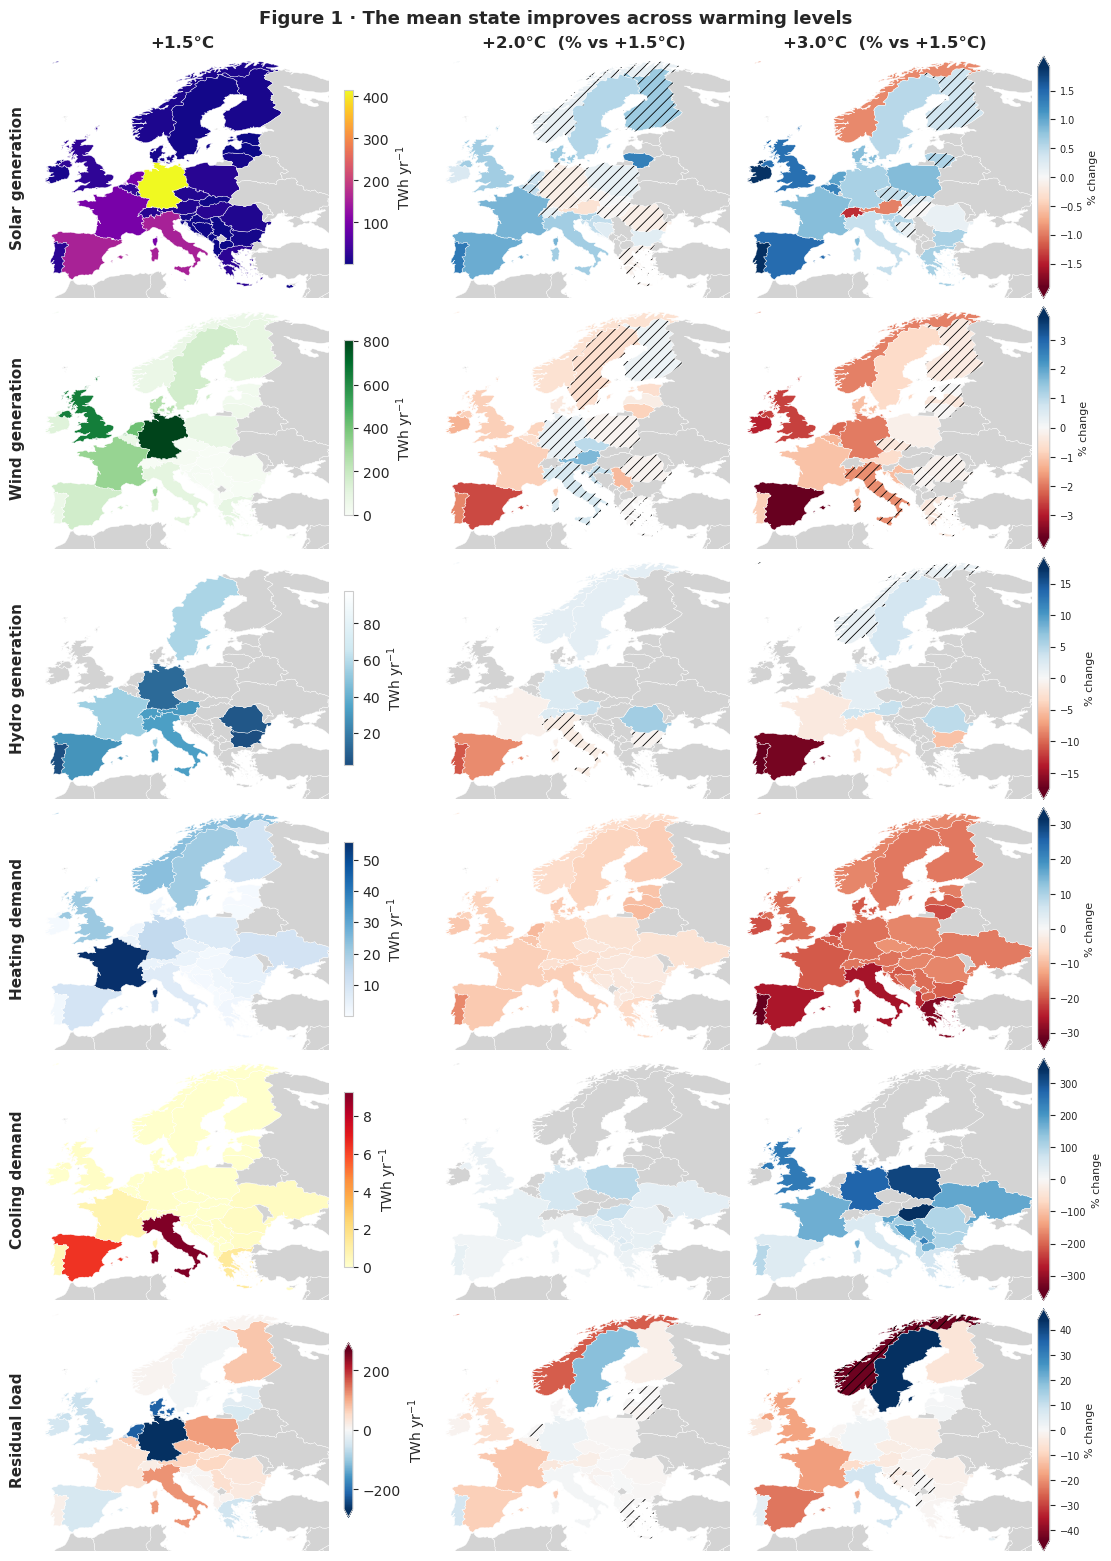

In [16]:
fig = plot_mean_state_maps(FIG1_QUANTITIES, countries, STYLE, compute_sign_agreement)
fig.savefig(FIGS / "fig1_mean_state.png", dpi=300, bbox_inches="tight")
plt.show()

## Figure 2 · The tail is where the stress lives

**(a)** Residual-load distributions per zone, in winter (DJF) and summer (JJA), at each warming level.
The **bulk shifts toward surplus** (left) — consistent with Fig 1 — while the **positive tail fattens**,
most strongly in the southern zones in summer. The dashed line is the season-specific **95th-percentile
CERRA threshold** that defines an extreme event for the rest of the paper.

**(b)** The two timescales part company. Annual deficit-hours in **sub-daily** (≤ 24 h) events grow by
about a third (**+32 %**), while the **multi-day** (> 24 h) burden is **flat (−2 %)** — not falling:
the northern multi-day decline is offset by the new Mediterranean summer regime (Fig 4). Two
timescales behaving differently is what motivates splitting the analysis into the regimes of
Figs 3 and 4.

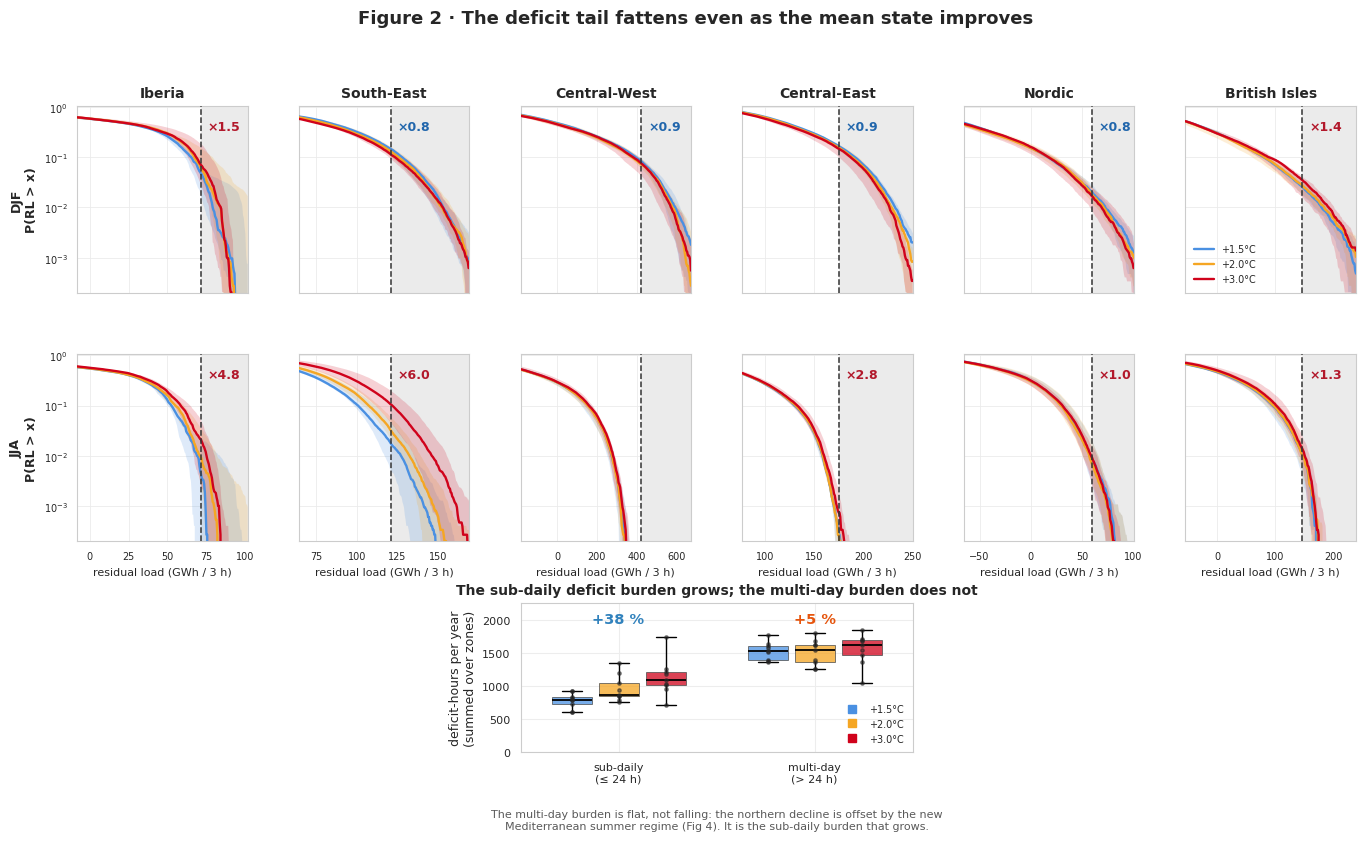

In [17]:
fig = plot_tail_survival(residual_load_by_model, period_defs, zone_threshold,
                         deficit_budget, STYLE, SEASON_MONTHS)
fig.savefig(FIGS / "fig2_tail.png", dpi=300, bbox_inches="tight")
plt.show()

## Figure 3 · The sub-daily regime — a southern surge of short evening deficits

**(a)** Short (≤ 24 h) events roughly **triple in Iberia (+169 %, 9/9 chains)** and rise **+60 %** in the
South-East, while they *fall* in the Nordic and continental zones — a **north–south dipole**.
**(b)** On stressed days the residual load is solar-shaped: it troughs at midday (PV covers the load)
and peaks in the **evening, 15–21 h — the only window that crosses the threshold**. That is *why* the
new stress is short.
**(c)** The rise is driven by **summer (JJA) demand** — air-conditioning load peaking after PV has faded.
In winter, evening demand *falls* in every zone.
**(d)** Storage absorbs **86–92 % of the severity** of these events in the southern zones — and yet the
number of exceedances still doubles. **Flexibility blunts these deficits; it does not prevent them.**

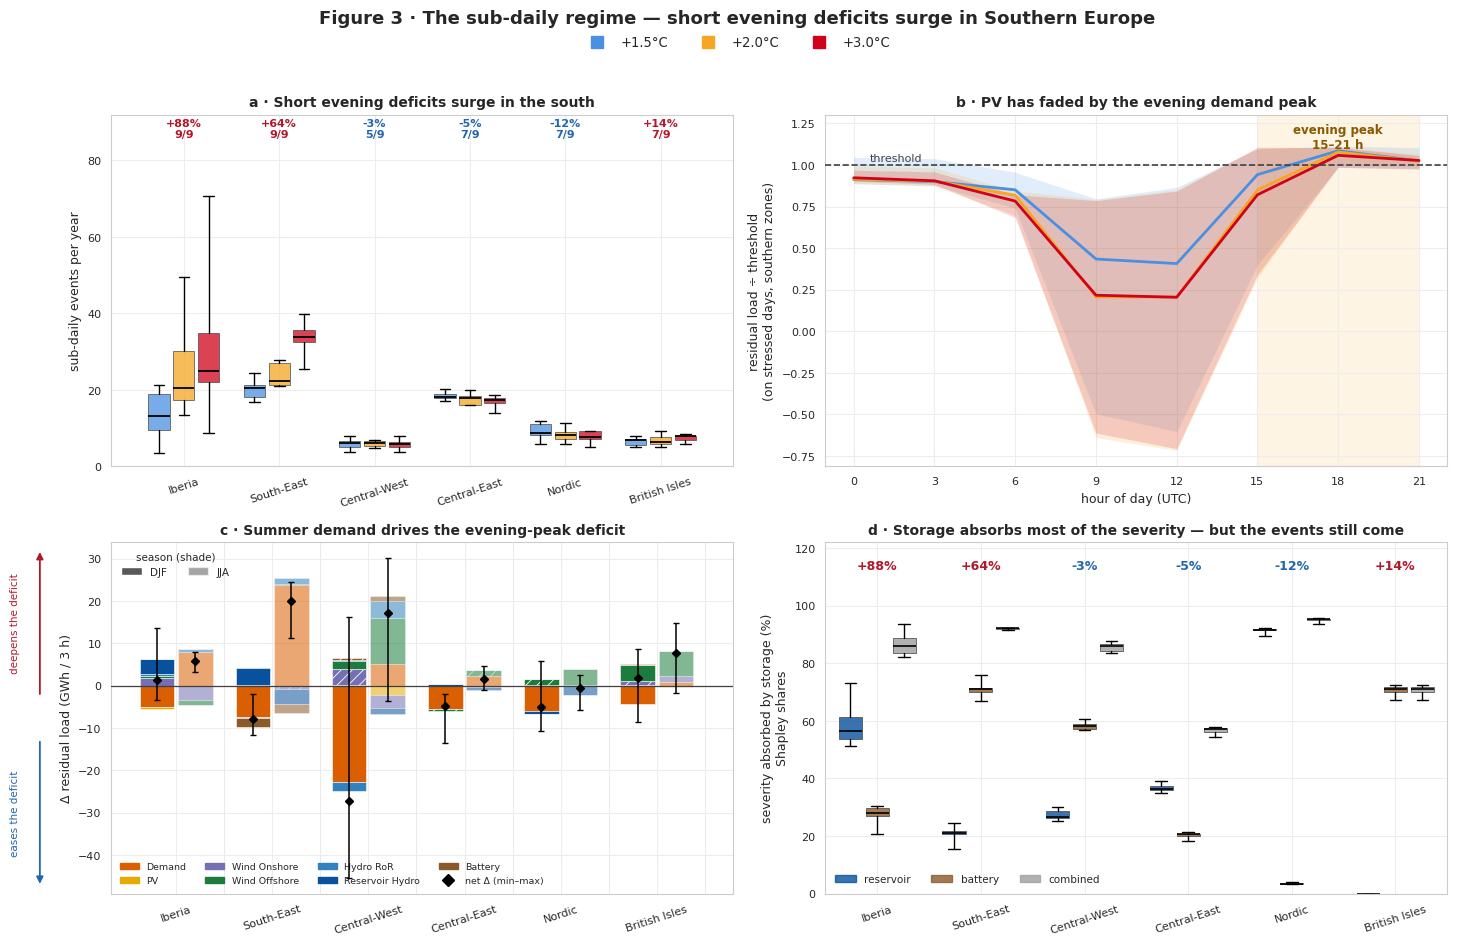

In [18]:
fig = plot_sub_daily_regime(events_annual, storage_attenuation, diurnal_profiles,
                            evening_peak_components, STYLE)
fig.savefig(FIGS / "fig3_sub_daily.png", dpi=300, bbox_inches="tight")
plt.show()

## Figure 4 · The multi-day regime — winter deficits ease, with two exceptions

Same layout as Fig 3, so the two regimes can be read against each other.

**(a)** Long (> 24 h) events **decline** where they dominate — Nordic **−44 %**, Central-East −14 %,
Central-West −15 % — but **rise in the British Isles (+31 %)** and the **South-East (+21 %)**.
**(b)** *The key panel.* Splitting by season shows the three mechanisms at once: the **winter decline**
across the north/continent; the British Isles rising in **every** season; and — new — a
**summer multi-day regime emerging from near-zero in the South-East (JJA 0.10 → 1.55 events/yr, ~15×)**:
persistent **heat-wave** deficits that outlast the diurnal solar cycle.
**(c)** Attribution **within season** (mandatory — pooling seasons would confound the South-East's
winter→summer recomposition). In **winter**, falling **heating demand** lowers the residual load so fewer
synoptic spells reach the threshold; in the **British Isles**, a declining **offshore wind** resource
cancels that relief. In **summer**, the South-East is driven by **cooling demand**.
**(d)** Storage is far weaker here than for the sub-daily regime — only **39 % in the British Isles** and
**41 % in Central-East**: a 4-hour battery cannot span a ~58-hour synoptic deficit. Where multi-day
events grow, flexibility helps least.

*The decline is a **level** effect, not a persistence effect: mean event duration (~58 h) is essentially
unchanged (Fig S16) — warming makes long deficits **rarer**, not **shorter**.*

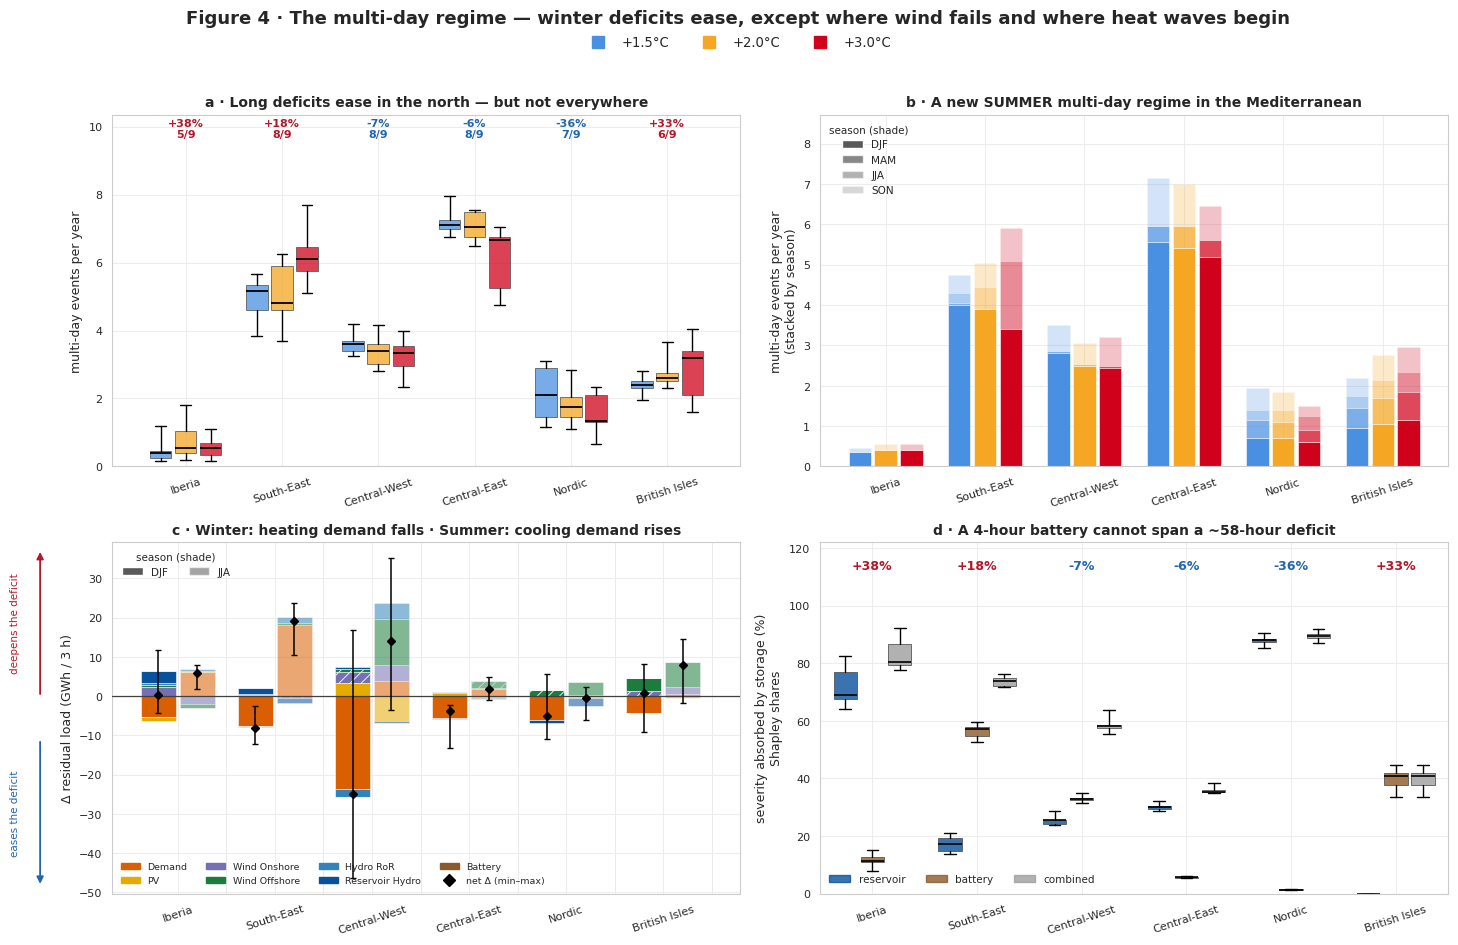

In [19]:
fig = plot_multi_day_regime(events_annual, storage_attenuation, multi_day_by_season,
                            multi_day_events, STYLE)
fig.savefig(FIGS / "fig4_multi_day.png", dpi=300, bbox_inches="tight")
plt.show()

---
# Supplementary figures

The SI lives in two companion notebooks, numbered contiguously **S1–S21**:

* **`paper_si_inputs.ipynb`  (S1–S7)** — the data behind the paper: the ensemble and its GWL windows,
  the balancing zones, the bias-corrected climate variables, the PV/wind capacity factors, the hydro
  fields, and the TYNDP-2024 scenario.
* **`paper_si_results.ipynb` (S8–S21)** — the results and the method defence: CERRA-vs-CORDEX
  calibration (**S8**), the threshold convention (**S9**, **S19**), the full residual-load and tail
  behaviour (**S10**, **S11**), the seasonal detail and significance behind Figs 3–4 (**S12**, **S13**),
  the attribution spread the stacked bars omit (**S14**), the diurnal mechanism (**S15**),
  level-vs-persistence (**S16**), co-occurrence (**S17**), unserved energy (**S18**), and the two
  counterfactuals that decide acceptance — scenario (**S20**) and flexibility (**S21**).

Cross-referenced from the main text above: **S16** is the level-vs-persistence result cited in Fig 4;
**S19** justifies the single absolute threshold used throughout.
